In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob

In [2]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

print("Real news articles:", len(real))
print("Fake news articles:", len(fake))

Real news articles: 21417
Fake news articles: 23481


In [3]:
real["Category"] = "Real News"
fake["Category"] = "Fake News"

news = pd.concat([real, fake], ignore_index=True)

news["title"] = news["title"].fillna("")
news["text"] = news["text"].fillna("")

news = news[
    (news["title"].str.strip() != "") &
    (news["text"].str.strip() != "")
].copy()

news = news.reset_index(drop=True)

news[["title", "text", "Category"]].head()

,title,text,Category
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,Real News
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,Real News
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,Real News
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,Real News
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,Real News


In [4]:
# Calculate Headline Polarity
news["Headline_Polarity"] = news["title"].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

news[["title", "Category", "Headline_Polarity"]].head()

,title,Category,Headline_Polarity
0,"As U.S. budget fight looms, Republicans flip t...",Real News,0.00
1,U.S. military to accept transgender recruits o...,Real News,-0.10
2,Senior U.S. Republican senator: 'Let Mr. Muell...,Real News,0.00
3,FBI Russia probe helped by Australian diplomat...,Real News,0.00
4,Trump wants Postal Service to charge 'much mor...,Real News,0.35


In [5]:
# Calculate Article Polarity
news["Article_Polarity"] = news["text"].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

news[["Category", "Headline_Polarity", "Article_Polarity"]].head()

,Category,Headline_Polarity,Article_Polarity
0,Real News,0.00,0.037083
1,Real News,-0.10,0.055880
2,Real News,0.00,0.115930
3,Real News,0.00,0.035968
4,Real News,0.35,0.030093


In [6]:
# Calculate the Polarity Shift
news["Polarity_Shift"] = (news["Headline_Polarity"] - news["Article_Polarity"])

news[
    ["title", "Category", "Headline_Polarity",
     "Article_Polarity", "Polarity_Shift"]
].head()

,title,Category,Headline_Polarity,Article_Polarity,Polarity_Shift
0,"As U.S. budget fight looms, Republicans flip t...",Real News,0.00,0.037083,-0.037083
1,U.S. military to accept transgender recruits o...,Real News,-0.10,0.055880,-0.155880
2,Senior U.S. Republican senator: 'Let Mr. Muell...,Real News,0.00,0.115930,-0.115930
3,FBI Russia probe helped by Australian diplomat...,Real News,0.00,0.035968,-0.035968
4,Trump wants Postal Service to charge 'much mor...,Real News,0.35,0.030093,0.319907


In [7]:
# Compare Average Polarity
polarity_summary = news.groupby("Category")[
    ["Headline_Polarity", "Article_Polarity", "Polarity_Shift"]
].mean()

polarity_summary.round(3)

,Headline_Polarity,Article_Polarity,Polarity_Shift
Category,,,
Fake News,0.003,0.061,-0.058
Real News,0.025,0.054,-0.029


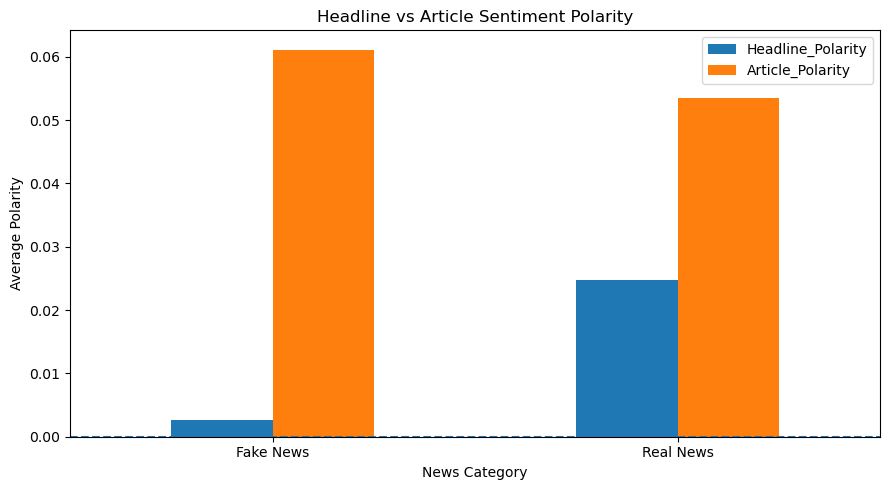

In [8]:
# Headline and Article Polarity
polarity_summary[["Headline_Polarity", "Article_Polarity"]].plot(kind="bar", figsize=(9, 5))

plt.title("Headline vs Article Sentiment Polarity")
plt.xlabel("News Category")
plt.ylabel("Average Polarity")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

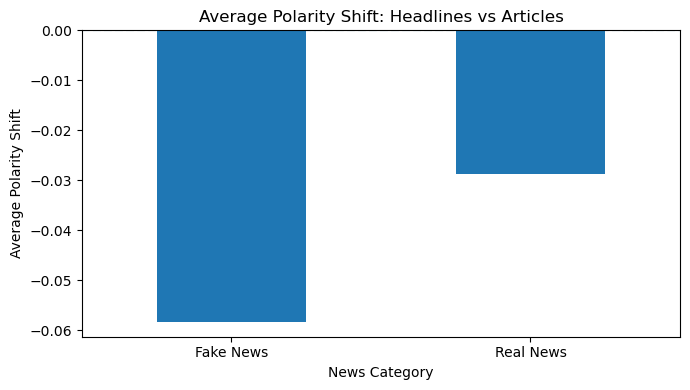

In [9]:
# Compare Polarity Shifts
shift_summary = news.groupby("Category")["Polarity_Shift"].mean()

shift_summary.plot(kind="bar", figsize=(7, 4))

plt.title("Average Polarity Shift: Headlines vs Articles")
plt.xlabel("News Category")
plt.ylabel("Average Polarity Shift")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Compare the Magnitude of Polarity Shifts
news["Absolute_Shift"] = news["Polarity_Shift"].abs()

magnitude_summary = news.groupby("Category")["Absolute_Shift"].mean()

magnitude_summary

Category
Fake News    0.227146
Real News    0.125119
Name: Absolute_Shift, dtype: float64

In [11]:
# Magnitude of Polarity Shifts

news["Absolute_Shift"] = news["Polarity_Shift"].abs()

magnitude_summary = news.groupby("Category")["Absolute_Shift"].mean()

magnitude_summary

Category
Fake News    0.227146
Real News    0.125119
Name: Absolute_Shift, dtype: float64

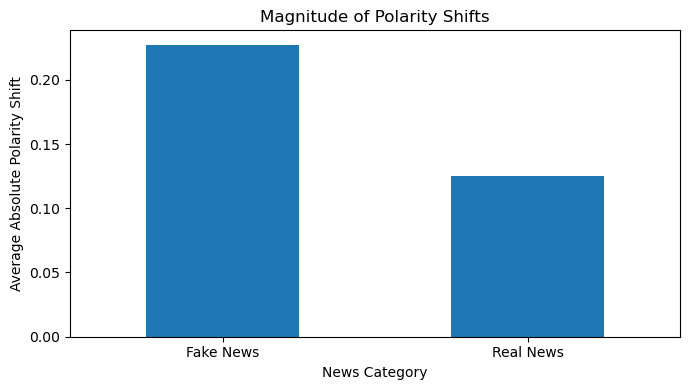

In [12]:
# Magnitude of Polarity Shifts
magnitude_summary.plot(kind="bar", figsize=(7, 4))

plt.title("Magnitude of Polarity Shifts")
plt.xlabel("News Category")
plt.ylabel("Average Absolute Polarity Shift")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Headlines with the Largest Polarity Shifts
largest_shifts = news.reindex(news["Absolute_Shift"].sort_values(ascending=False).index)

largest_shifts[["Category", "title", "Headline_Polarity", "Article_Polarity", "Polarity_Shift"]].head(10)

,Category,title,Headline_Polarity,Article_Polarity,Polarity_Shift
41204,Fake News,LOL! CONSERVATIVE COMEDIAN Steven Crowder Make...,1.0,-1.000000,2.000000
40349,Fake News,DEMOCRATS AREN’T AFRAID Trump Will Be A Terrib...,-0.8,0.950000,-1.750000
33415,Fake News,DEMOCRATS AREN’T AFRAID Trump Will Be A Terrib...,-0.8,0.950000,-1.750000
37304,Fake News,OBAMACARE LOAN SHARK: If Gov’t Can Extort More...,0.5,-1.000000,1.500000
35578,Fake News,HYSTERICAL! HERE’S HILLARY Yelling It Out On T...,-1.0,0.500000,-1.500000
33736,Fake News,OBAMACARE LOAN SHARK: If Gov’t Can Extort More...,0.5,-1.000000,1.500000
34216,Fake News,HYSTERICAL! HILLARY’S SPEECH HIJACKED By Conse...,-1.0,0.412500,-1.412500
34885,Fake News,HYSTERICAL! MSNBC Host Gets Rapists confused…C...,-1.0,0.372222,-1.372222
41333,Fake News,HYSTERICAL! MSNBC Host Gets Rapists confused…C...,-1.0,0.372222,-1.372222
36420,Fake News,(VIDEO) FRIDAY NIGHT’S HYSTERICAL TAKE ON THE ...,-1.0,0.366667,-1.366667
